# Step 6 - Customer Segmentation and Lifetime Value
**Objective 4:** group customers into meaningful segments with K-Means on RFM, and estimate each customer's **customer lifetime value (CLV)** with the BG/NBD and Gamma-Gamma models.

**Input:** `data/clean_sales.csv` (Step 1), `data/churn_dataset.csv` (Step 3) and `data/churn_predictions_test.csv` (Step 4). Click **Run All** (about 1 minute).

| Part | What happens |
|---|---|
| RFM | Recency, Frequency and Monetary value are rebuilt from the sales data at the **1 Jul 2011** cut-off and checked against Step 3 |
| Segmentation | K-Means on log-transformed, standardised RFM. The number of segments is chosen with silhouette, Davies-Bouldin and stability checks, then every segment is profiled |
| CLV model | **BG/NBD** predicts how many purchases each customer will make; **Gamma-Gamma** predicts how much each purchase is worth. Expected purchases x expected value = expected revenue |
| Validation | The CLV model is fitted on data before a cut-off and compared with what customers **really** did in the next 150 days (two cut-offs) |
| Hand-off | Per-customer segment, CLV and value tier for Step 8 (retention rules), Step 9 (simulation) and Step 10 (dashboard) |

**Outputs:** `data/customer_value_test.csv`, `data/customer_value_current.csv`, `data/segment_profiles.csv`, `data/clv_validation.csv`, `models/segmentation_clv_params.json`, `segmentation_clv_summary.txt` and charts `figures/seg_*.png`, `figures/clv_*.png`.

### Plain-language guide
* **RFM:** how *recently* a customer bought, how *often*, and how *much* they spent. Customers with similar RFM form a segment.
* **BG/NBD:** every customer buys at their own steady pace (some often, some rarely) and, after each purchase, has a small chance of leaving for good. The model learns how these paces and leaving chances vary across customers, then predicts future purchases from each customer's own history.
* **Gamma-Gamma:** a customer's typical purchase value is stable but noisy. The model pulls a customer's average towards the overall average, more strongly when the customer has few purchases, so a single huge order does not create a fake "big spender".
* **CLV here = expected revenue over the next 12 months** (discounted at 1% per month). There is no cost or margin data, so it is *revenue*, not profit.

I implemented BG/NBD and Gamma-Gamma directly (the formulas are in the sections below and are tested on simulated data) because the `lifetimes` package is no longer reliably maintained and often fails to install on current Python versions. Section 12 optionally cross-checks with it if it is installed.

## 1. Setup and data

In [1]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import gammaln, hyp2f1
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, roc_auc_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from IPython.display import display

warnings.filterwarnings("ignore")
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.max_columns = 40
pd.options.display.width = 200
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

DATA, FIG, MODELS = Path("data"), Path("figures"), Path("models")
for d in (FIG, MODELS):
    d.mkdir(exist_ok=True)
SEED = 42

# --- definitions shared with Steps 3 and 4 -----------------------------------
TEST_CUTOFF = pd.Timestamp("2011-07-01")     # the churn test snapshot
HORIZON_DAYS = 150                           # outcome window used for churn
LOOKBACK_DAYS = 365                          # customers must have bought in the 365 days before the cut-off
BACKTEST_CUTOFFS = [pd.Timestamp("2010-12-31"), TEST_CUTOFF]   # both outcome windows are fully observed

# --- CLV settings --------------------------------------------------------------
CLV_MONTHS = 12                              # CLV horizon
DAYS_PER_MONTH = 30
DISCOUNT_MONTHLY = 0.01                      # 1% per month, about 12.7% per year
TIER_SPLIT = (0.20, 0.30, 0.50)              # High / Medium / Low value, same split as the churn RiskTier

# --- segmentation settings -----------------------------------------------------
K_RANGE = range(2, 9)
K_MIN = 3                                    # at least three segments are needed to tell customers apart for different actions
K_OVERRIDE = None                            # set an integer here to force a particular number of segments

# Orders cancelled in full (the same three very large orders removed in Step 2 and in the recommender)
CANCELLED_IN_FULL = [541431, 556444, 581483]

## 2. Load the data and rebuild RFM

Customers are described **as of a cut-off date, using only purchases before it**. A *purchase day* is a day on which the customer placed one or more orders (the same definition as `AvgGapDays` in Step 3), and its value is that day's total revenue. The RFM columns reproduce Step 3 exactly (the check below enforces this for the test snapshot).

In [2]:
sales = pd.read_csv(DATA / "clean_sales.csv", parse_dates=["InvoiceDate"], dtype={"StockCode": str})
sales = sales[~sales["Invoice"].isin(CANCELLED_IN_FULL)].copy()
sales["Day"] = sales["InvoiceDate"].dt.normalize()

churn_ds = pd.read_csv(DATA / "churn_dataset.csv", parse_dates=["SnapshotDate", "WindowEnd"])
churn_test = churn_ds[churn_ds["Split"] == "test"].set_index("CustomerID")
pred = pd.read_csv(DATA / "churn_predictions_test.csv").set_index("CustomerID")
print(f"Sales lines {len(sales):,}, customers {sales['CustomerID'].nunique():,}, {sales['Day'].min():%d %b %Y} to {sales['Day'].max():%d %b %Y}")


def customer_summary(sales, cutoff):
    """One row per customer who bought before the cut-off (features use only data before it)."""
    cutoff = pd.Timestamp(cutoff).normalize()
    tr = sales[sales["Day"] < cutoff]
    daily = tr.groupby(["CustomerID", "Day"], as_index=False)["Revenue"].sum()          # revenue per purchase day
    g = daily.groupby("CustomerID").agg(PurchaseDays=("Day", "size"), FirstDay=("Day", "min"),
                                        LastDay=("Day", "max"), MeanDayValue=("Revenue", "mean"))
    g = g.join(tr.groupby("CustomerID").agg(Frequency=("Invoice", "nunique"), Monetary=("Revenue", "sum")))
    g["Recency"] = (cutoff - g["LastDay"]).dt.days                     # days since last purchase (as in Step 3)
    g["x"] = g["PurchaseDays"] - 1                                     # repeat purchase days
    g["t_x"] = (g["LastDay"] - g["FirstDay"]).dt.days.astype(float)    # days between first and last purchase
    g["T"] = (cutoff - g["FirstDay"]).dt.days.astype(float)            # days since first purchase
    g["Active"] = g["Recency"] <= LOOKBACK_DAYS                        # bought in the last 365 days
    return g


summ_test = customer_summary(sales, TEST_CUTOFF)
elig_test = summ_test[summ_test["Active"]]

# --- the RFM values and the customer list must match Step 3 exactly ------------
assert set(elig_test.index) == set(churn_test.index), "active customers differ from the churn test set"
chk = elig_test.loc[churn_test.index]
assert (chk["Recency"] == churn_test["Recency"]).all() and (chk["Frequency"] == churn_test["Frequency"]).all()
assert np.allclose(chk["Monetary"], churn_test["Monetary"])
print(f"\nCustomers who bought before {TEST_CUTOFF:%d %b %Y}: {len(summ_test):,}; active in the last {LOOKBACK_DAYS} days: {len(elig_test):,}")
print("RFM rebuilt from clean_sales.csv matches Step 3 exactly (Recency, Frequency, Monetary)  ✓")
display(elig_test[["Recency", "Frequency", "Monetary"]].describe().loc[["mean", "min", "25%", "50%", "75%", "max"]])

Sales lines 776,572, customers 5,852, 01 Dec 2009 to 09 Dec 2011

Customers who bought before 01 Jul 2011: 5,016; active in the last 365 days: 4,313
RFM rebuilt from clean_sales.csv matches Step 3 exactly (Recency, Frequency, Monetary)  ✓


,Recency,Frequency,Monetary
mean,132.791,5.986,"2,713.391"
min,1.000,1.000,2.900
25%,36.000,2.000,376.500
50%,103.000,3.000,911.320
75%,228.000,7.000,"2,255.800"
max,365.000,251.000,"427,931.290"


## 3. Customer segmentation with K-Means

**Preparation.** RFM values are very skewed (a few customers spend hundreds of thousands), so each is transformed with `log(1 + x)` and then standardised, so that the three measures count equally in the distance calculation. In the log scale Frequency and Monetary are strongly correlated, so in practice the segments are separated mainly by *how recently* and *how much and how often* customers buy.

**Choosing the number of segments (k).** For each k from 2 to 8 the notebook reports:

* **Silhouette** (higher is better; how well each customer fits its own segment compared with the next-best segment)
* **Davies-Bouldin index** (lower is better; how separated the segments are)
* **Stability** (higher is better): the average Adjusted Rand Index between the segmentation of all customers and re-segmentations of random 80% samples. Close to 1 means the same customers land together every time.
* **Inertia** (the "elbow" curve; always falls as k grows)

The rule is: *choose the k with the highest silhouette among k >= 3*. Two segments would only separate recent from lapsed customers, which is too coarse for different retention actions.

Correlation of the log-RFM measures (R, F, M):


,Recency,Frequency,Monetary
Recency,1.000,-0.500,-0.428
Frequency,-0.500,1.000,0.848
Monetary,-0.428,0.848,1.000


,Inertia,Silhouette,Davies-Bouldin,Stability (ARI),Smallest segment
k,,,,,
2,"6,579.527",0.436,0.901,0.987,1609
3,"5,031.124",0.338,1.062,0.903,755
4,"3,820.155",0.365,0.918,0.972,698
5,"3,208.111",0.326,0.962,0.953,446
6,"2,818.415",0.322,0.945,0.954,369
7,"2,560.563",0.286,1.016,0.817,290
8,"2,317.769",0.293,0.985,0.830,221


Highest silhouette overall: k = 2; highest among k >= 3: k = 4
Selected number of segments: k = 4
Silhouette of the selected solution is 0.37: values of 0.25-0.5 mean real but overlapping structure, i.e. customers form a continuum and the segments are useful divisions of it, not separate natural groups.


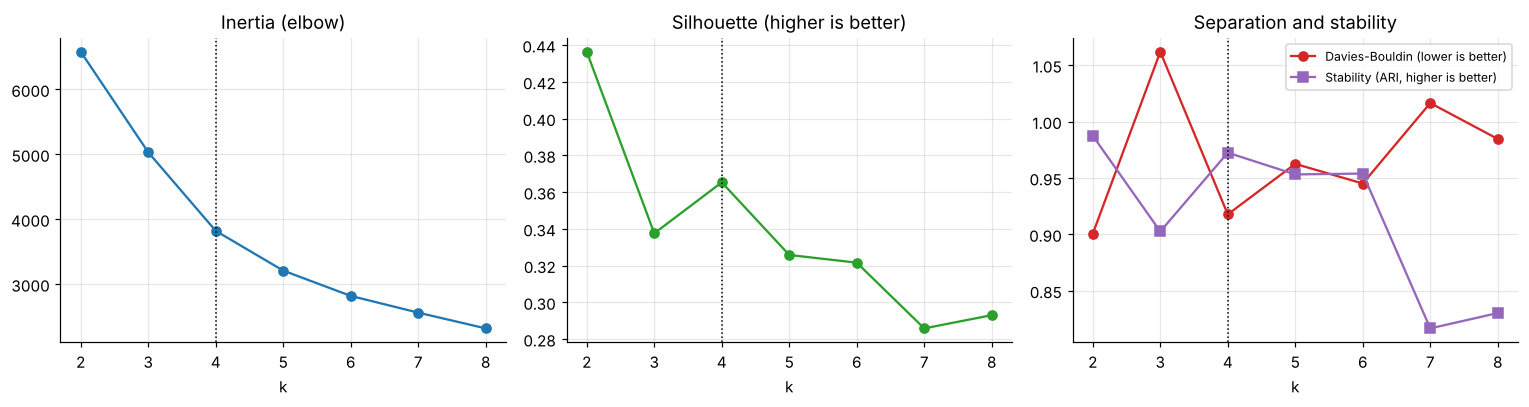

In [3]:
X_rfm = np.log1p(elig_test[["Recency", "Frequency", "Monetary"]].to_numpy(dtype=float))
scaler = StandardScaler().fit(X_rfm)
Xs = scaler.transform(X_rfm)
print("Correlation of the log-RFM measures (R, F, M):")
display(pd.DataFrame(np.corrcoef(Xs.T), index=["Recency", "Frequency", "Monetary"], columns=["Recency", "Frequency", "Monetary"]))

rows, rs = [], np.random.default_rng(SEED)
for k in K_RANGE:
    km = KMeans(k, n_init=20, random_state=SEED).fit(Xs)
    aris = []
    for _ in range(10):                                                 # stability on random 80% samples
        idx = rs.choice(len(Xs), int(0.8 * len(Xs)), replace=False)
        km2 = KMeans(k, n_init=5, random_state=int(rs.integers(1e6))).fit(Xs[idx])
        aris.append(adjusted_rand_score(km.labels_[idx], km2.labels_))
    rows.append({"k": k, "Inertia": km.inertia_, "Silhouette": silhouette_score(Xs, km.labels_),
                 "Davies-Bouldin": davies_bouldin_score(Xs, km.labels_), "Stability (ARI)": np.mean(aris),
                 "Smallest segment": int(np.bincount(km.labels_).min())})
k_table = pd.DataFrame(rows).set_index("k")
display(k_table)

eligible_k = k_table[k_table.index >= K_MIN]
best_k = int(eligible_k["Silhouette"].idxmax()) if K_OVERRIDE is None else int(K_OVERRIDE)
print(f"Highest silhouette overall: k = {int(k_table['Silhouette'].idxmax())}; highest among k >= {K_MIN}: k = {int(eligible_k['Silhouette'].idxmax())}")
print(f"Selected number of segments: k = {best_k}" + ("" if K_OVERRIDE is None else "  (set manually)"))
print(f"Silhouette of the selected solution is {k_table.loc[best_k, 'Silhouette']:.2f}: values of 0.25-0.5 mean real but overlapping structure, "
      f"i.e. customers form a continuum and the segments are useful divisions of it, not separate natural groups.")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].plot(k_table.index, k_table["Inertia"], marker="o"); ax[0].set_title("Inertia (elbow)"); ax[0].set_xlabel("k")
ax[1].plot(k_table.index, k_table["Silhouette"], marker="o", color="tab:green"); ax[1].set_title("Silhouette (higher is better)"); ax[1].set_xlabel("k")
ax[2].plot(k_table.index, k_table["Davies-Bouldin"], marker="o", color="tab:red", label="Davies-Bouldin (lower is better)")
ax[2].plot(k_table.index, k_table["Stability (ARI)"], marker="s", color="tab:purple", label="Stability (ARI, higher is better)")
ax[2].set_title("Separation and stability"); ax[2].set_xlabel("k"); ax[2].legend(fontsize=8)
for a in ax:
    a.axvline(best_k, color="k", ls=":", lw=1)
plt.tight_layout(); plt.savefig(FIG / "seg_choose_k.png", dpi=120); plt.show()

## 4. Profile the segments

Each segment is described in the original units (medians, which are not distorted by a few giant customers). The last columns show what happened **afterwards**, from the churn notebooks: the actual churn rate and the Step 4 model's average predicted churn probability. These outcomes are **not** used to form the segments; they only show whether the segments are meaningful (segments that really differ in later behaviour are useful).

Segments are numbered from the highest to the lowest median spend and named by a simple rule on the median Recency and Frequency compared with all customers (recent = shorter than the overall median recency; very frequent = at or above the 75th percentile of frequency; regular = above the median frequency). Rename them in `SEGMENT_NAMES` below if you prefer other labels.

In [4]:
km = KMeans(best_k, n_init=50, random_state=SEED).fit(Xs)
seg = pd.Series(km.labels_, index=elig_test.index)

# number segments 1..k from highest to lowest median spend
order = elig_test.groupby(seg)["Monetary"].median().sort_values(ascending=False).index
relabel = {old: new for new, old in enumerate(order, start=1)}
seg = seg.map(relabel)
centers = km.cluster_centers_[list(order)]                              # centroids in the new order (scaled log space)

ref = {"R50": elig_test["Recency"].median(), "F50": elig_test["Frequency"].median(), "F75": elig_test["Frequency"].quantile(0.75)}

def name_segment(R, F):
    recent = R <= ref["R50"]
    if recent and F >= ref["F75"]:
        return "Champions"
    if recent:
        return "Recent / developing customers"
    if F > ref["F50"]:
        return "At-risk regulars"
    return "Lapsed low-frequency customers"

med = elig_test.groupby(seg)[["Recency", "Frequency", "Monetary"]].median()
names = {s: name_segment(r.Recency, r.Frequency) for s, r in med.iterrows()}
dup = pd.Series(names).duplicated(keep=False)
for s in sorted(names):                                                  # make duplicate names unique
    if dup[s]:
        names[s] = f"{names[s]} ({s})"
SEGMENT_NAMES = names                                                    # edit here to rename
print("Segment names:", SEGMENT_NAMES)

prof_df = elig_test.assign(Segment=seg.map(SEGMENT_NAMES), SegmentID=seg)
prof_df = prof_df.join(churn_test[["Churn", "Outcome_FutureSpend"]]).join(pred[["ChurnProbability", "RiskTier", "Country"]])
prof = prof_df.groupby("SegmentID").agg(
    Segment=("Segment", "first"), Customers=("Frequency", "size"),
    MedianRecency=("Recency", "median"), MedianFrequency=("Frequency", "median"), MedianMonetary=("Monetary", "median"),
    MedianOrderValue=("MeanDayValue", "median"), TotalSpend=("Monetary", "sum"),
    ActualChurnRate=("Churn", "mean"), AvgPredictedChurn=("ChurnProbability", "mean"), FutureSpend=("Outcome_FutureSpend", "sum"))
prof["ShareOfCustomers"] = prof["Customers"] / prof["Customers"].sum()
prof["ShareOfPastSpend"] = prof["TotalSpend"] / prof["TotalSpend"].sum()
prof["ShareOfFutureSpend"] = prof["FutureSpend"] / prof["FutureSpend"].sum()
prof = prof.drop(columns=["TotalSpend", "FutureSpend"])
display(prof)

for s, r in prof.iterrows():
    print(f"* {r['Segment']}: {r['Customers']:,.0f} customers ({r['ShareOfCustomers']:.0%}); last bought a median {r['MedianRecency']:.0f} days ago, "
          f"{r['MedianFrequency']:.0f} orders, {r['MedianMonetary']:,.0f} spent; {r['ShareOfPastSpend']:.0%} of past spend; "
          f"{r['ActualChurnRate']:.0%} later churned.")

Segment names: {1: 'Champions', 2: 'At-risk regulars', 3: 'Recent / developing customers', 4: 'Lapsed low-frequency customers'}


,Segment,Customers,MedianRecency,MedianFrequency,MedianMonetary,MedianOrderValue,ActualChurnRate,AvgPredictedChurn,ShareOfCustomers,ShareOfPastSpend,ShareOfFutureSpend
SegmentID,,,,,,,,,,,
1,Champions,698,21.000,14.000,"5,399.160",419.151,0.069,0.135,0.162,0.658,0.665
2,At-risk regulars,1284,148.000,5.000,"1,612.605",344.618,0.425,0.521,0.298,0.229,0.183
3,Recent / developing customers,715,22.000,3.000,865.680,264.452,0.344,0.436,0.166,0.061,0.094
4,Lapsed low-frequency customers,1616,225.000,1.000,321.475,220.285,0.699,0.683,0.375,0.052,0.058


* Champions: 698 customers (16%); last bought a median 21 days ago, 14 orders, 5,399 spent; 66% of past spend; 7% later churned.
* At-risk regulars: 1,284 customers (30%); last bought a median 148 days ago, 5 orders, 1,613 spent; 23% of past spend; 43% later churned.
* Recent / developing customers: 715 customers (17%); last bought a median 22 days ago, 3 orders, 866 spent; 6% of past spend; 34% later churned.
* Lapsed low-frequency customers: 1,616 customers (37%); last bought a median 225 days ago, 1 orders, 321 spent; 5% of past spend; 70% later churned.


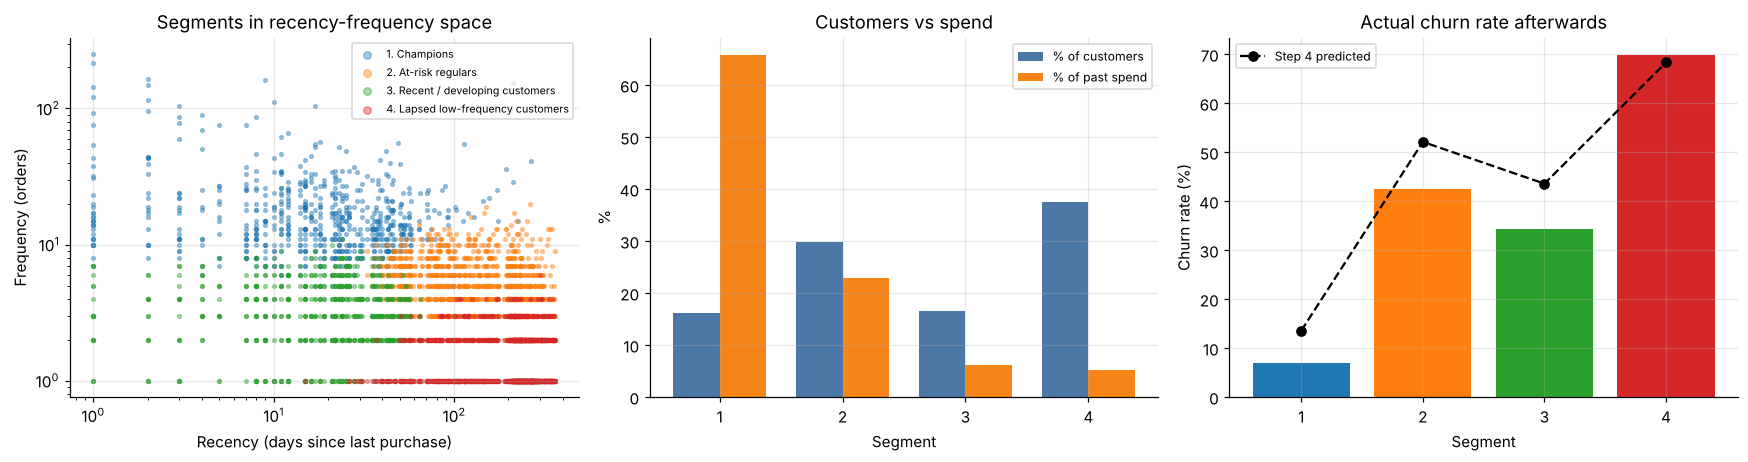

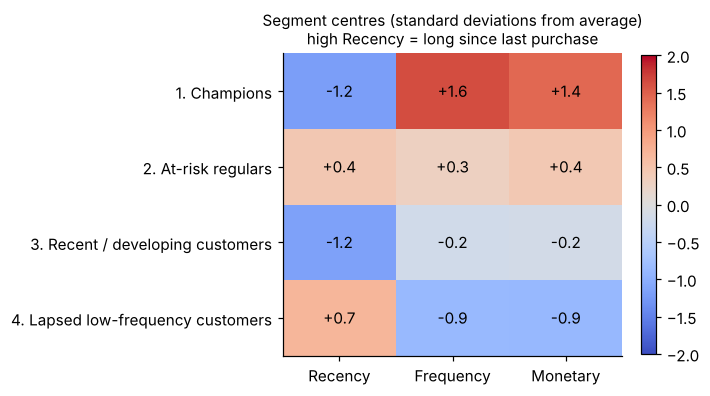

In [5]:
colors = plt.cm.tab10(np.arange(best_k))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))

# scatter: recency vs frequency (log scales), coloured by segment
for s in sorted(SEGMENT_NAMES):
    m = (seg == s).to_numpy()
    ax[0].scatter(elig_test.loc[m, "Recency"], elig_test.loc[m, "Frequency"], s=6, alpha=0.4, color=colors[s - 1], label=f"{s}. {SEGMENT_NAMES[s]}")
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("Recency (days since last purchase)"); ax[0].set_ylabel("Frequency (orders)")
ax[0].set_title("Segments in recency-frequency space"); ax[0].legend(fontsize=7, markerscale=2)

# share of customers vs share of spend
w = 0.38; x = np.arange(best_k)
ax[1].bar(x - w / 2, prof["ShareOfCustomers"] * 100, w, label="% of customers", color="#4C78A8")
ax[1].bar(x + w / 2, prof["ShareOfPastSpend"] * 100, w, label="% of past spend", color="#F58518")
ax[1].set_xticks(x); ax[1].set_xticklabels([f"{s}" for s in prof.index]); ax[1].set_xlabel("Segment"); ax[1].set_ylabel("%"); ax[1].legend(fontsize=8)
ax[1].set_title("Customers vs spend")

# later behaviour
ax[2].bar(x, prof["ActualChurnRate"] * 100, color=colors[:best_k])
ax[2].plot(x, prof["AvgPredictedChurn"] * 100, "ko--", label="Step 4 predicted")
ax[2].set_xticks(x); ax[2].set_xticklabels([f"{s}" for s in prof.index]); ax[2].set_xlabel("Segment"); ax[2].set_ylabel("Churn rate (%)")
ax[2].set_title("Actual churn rate afterwards"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "seg_profiles.png", dpi=120); plt.show()

# centroid heat map (standardised log-RFM): red = above average, blue = below average
fig, ax = plt.subplots(figsize=(6.5, 0.9 + 0.7 * best_k))
im = ax.imshow(centers, cmap="coolwarm", vmin=-2, vmax=2, aspect="auto"); ax.grid(False)
ax.set_xticks(range(3)); ax.set_xticklabels(["Recency", "Frequency", "Monetary"])
ax.set_yticks(range(best_k)); ax.set_yticklabels([f"{s}. {SEGMENT_NAMES[s]}" for s in sorted(SEGMENT_NAMES)])
for i in range(best_k):
    for j in range(3):
        ax.text(j, i, f"{centers[i, j]:+.1f}", ha="center", va="center", fontsize=10)
ax.set_title("Segment centres (standard deviations from average)\nhigh Recency = long since last purchase", fontsize=10)
plt.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout(); plt.savefig(FIG / "seg_centroids.png", dpi=120); plt.show()

## 5. The CLV models

### BG/NBD: how many purchases will a customer make?
For each customer the model only needs three numbers, computed from purchase days before the cut-off:

* **x** = number of *repeat* purchase days (purchase days minus one)
* **t_x** = days between the first and the last purchase
* **T** = days from the first purchase to the cut-off

It has four parameters learned from all customers: the purchase rate varies between customers as a Gamma distribution (`r`, `alpha`), and the chance of leaving for good after each purchase varies as a Beta distribution (`a`, `b`). It then gives, for any customer, the **expected number of purchases in the next t days** and the **probability the customer is still "alive"**. (A customer with a single purchase is "alive" with probability 1 by construction, which matters later.)

### Gamma-Gamma: how much will each purchase be worth?
Each customer has a typical purchase value (`n` purchase days with an average value `m`). Gamma-Gamma estimates the customer's true typical value as a compromise between their own average and the overall average, trusting the customer's own history more when `n` is large. It assumes a customer's purchase value is unrelated to how often they buy (checked below).

### CLV
`CLV = sum over the next 12 months of (expected purchases in that month x expected value per purchase) / (1 + 1%)^month`

In [6]:
# ---------------------------------------------------------------- BG/NBD (Fader, Hardie & Lee, 2005)
def bgnbd_nll(log_params, x, t_x, T):
    """Negative log-likelihood of the BG/NBD model."""
    r, alpha, a, b = np.exp(log_params)
    base = (gammaln(r + x) - gammaln(r) + r * np.log(alpha) + gammaln(a + b) + gammaln(b + x)
            - gammaln(b) - gammaln(a + b + x))
    term_alive = -(r + x) * np.log(alpha + T)
    bx = np.where(x > 0, b + x - 1, 1.0)
    term_dead = np.log(a) - np.log(bx) - (r + x) * np.log(alpha + t_x)
    inner = np.where(x > 0, np.logaddexp(term_alive, term_dead), term_alive)
    return -(base + inner).sum()


def fit_bgnbd(x, t_x, T):
    best = None
    for start in ((0.5, 50.0, 1.0, 2.0), (1.0, 100.0, 0.5, 1.0), (0.3, 30.0, 2.0, 5.0)):   # several starts, keep the best
        res = minimize(bgnbd_nll, np.log(start), args=(x, t_x, T), method="L-BFGS-B")
        if best is None or res.fun < best.fun:
            best = res
    return dict(zip(["r", "alpha", "a", "b"], np.exp(best.x))), best


def p_alive(p, x, t_x, T):
    """Probability that the customer has not yet left for good."""
    r, alpha, a, b = p["r"], p["alpha"], p["a"], p["b"]
    bx = np.where(x > 0, b + x - 1, 1.0)
    odds = np.where(x > 0, a / bx * np.exp((r + x) * (np.log(alpha + T) - np.log(alpha + t_x))), 0.0)
    return 1 / (1 + odds)


def expected_purchases(p, t, x, t_x, T):
    """Expected number of purchase days in the next t days, given the customer's history."""
    r, alpha, a, b = p["r"], p["alpha"], p["a"], p["b"]
    z = t / (alpha + T + t)
    lead = (a + b + x - 1) / (a - 1)
    term = 1 - np.exp((r + x) * (np.log(alpha + T) - np.log(alpha + T + t))) * hyp2f1(r + x, b + x, a + b + x - 1, z)
    return np.maximum(lead * term * p_alive(p, x, t_x, T), 0.0)


# ---------------------------------------------------------------- Gamma-Gamma (Fader & Hardie, 2013)
def gg_nll(log_params, n, m):
    p, q, g = np.exp(log_params)
    ll = (gammaln(p * n + q) - gammaln(p * n) - gammaln(q) + q * np.log(g) + (p * n - 1) * np.log(m)
          + p * n * np.log(n) - (p * n + q) * np.log(g + n * m))
    return -ll.sum()


def fit_gg(n, m):
    best = None
    for start in ((2.0, 3.0, 100.0), (1.0, 2.0, 50.0), (3.0, 5.0, 300.0)):
        res = minimize(gg_nll, np.log(start), args=(n, m), method="L-BFGS-B")
        if best is None or res.fun < best.fun:
            best = res
    return dict(zip(["p", "q", "gamma"], np.exp(best.x))), best


def gg_expected_value(g, n, m):
    """Expected typical purchase value: the customer's own average shrunk towards the overall average."""
    return g["p"] * (g["gamma"] + n * m) / (g["p"] * n + g["q"] - 1)

### 5.1 Test the implementation on simulated customers

Before trusting the models on real data, they are tested on **artificial customers generated from known parameters**. If the code is right, fitting should recover the true parameters, and the predicted future purchases should match the simulated future purchases.

In [7]:
g = np.random.default_rng(SEED)
true_bg = dict(r=0.8, alpha=70.0, a=1.6, b=3.2)
N, H = 3000, 150
Ts = g.uniform(60, 500, N)
lam = g.gamma(true_bg["r"], 1 / true_bg["alpha"], N)           # purchase rate of each customer
leave = g.beta(true_bg["a"], true_bg["b"], N)                   # chance of leaving after each purchase
sx, stx, fut_sim = np.zeros(N), np.zeros(N), np.zeros(N)
for i in range(N):
    t, k, last, dead = 0.0, 0, 0.0, False
    while True:                                                 # history up to T
        t += g.exponential(1 / lam[i])
        if t > Ts[i]:
            break
        k, last = k + 1, t
        if g.random() < leave[i]:
            dead = True
            break
    sx[i], stx[i] = k, last
    if not dead:                                                # real future purchases in the next H days
        t = Ts[i]
        while True:
            t += g.exponential(1 / lam[i])
            if t > Ts[i] + H:
                break
            fut_sim[i] += 1
            if g.random() < leave[i]:
                break

est, _ = fit_bgnbd(sx, stx, Ts)
leave_true, leave_est = true_bg["a"] / (true_bg["a"] + true_bg["b"]), est["a"] / (est["a"] + est["b"])
rel = {"r": abs(est["r"] / true_bg["r"] - 1), "alpha": abs(est["alpha"] / true_bg["alpha"] - 1), "a/(a+b)": abs(leave_est / leave_true - 1)}
print("BG/NBD parameters   true     recovered")
for k in true_bg:
    print(f"  {k:6s}          {true_bg[k]:6.2f}   {est[k]:8.2f}")
print(f"  a/(a+b)         {leave_true:6.2f}   {leave_est:8.2f}   <- average chance of leaving after a purchase")
print("(a and b are only weakly identifiable separately - different pairs describe almost the same customers - so the check uses their ratio.)")
pred_sim = expected_purchases(est, H, sx, stx, Ts)
print(f"\nFuture purchases in the next {H} days (per customer): predicted {pred_sim.mean():.3f}, simulated truth {fut_sim.mean():.3f}")

# Gamma-Gamma on simulated purchase values
true_gg = dict(p=2.5, q=4.0, gamma=120.0)
nu = g.gamma(true_gg["q"], 1 / true_gg["gamma"], 4000)
n_s = g.integers(1, 15, 4000).astype(float)
m_s = np.array([g.gamma(true_gg["p"] * k, 1 / (v * k)) for k, v in zip(n_s, nu)])
est_g, _ = fit_gg(n_s, m_s)
print("\nGamma-Gamma parameters   true     recovered")
for k in true_gg:
    print(f"  {k:6s}               {true_gg[k]:6.2f}   {est_g[k]:8.2f}")
true_mean = true_gg["p"] / nu
err_model = np.abs(gg_expected_value(est_g, n_s, m_s) - true_mean).mean()
err_naive = np.abs(m_s - true_mean).mean()
print(f"Error in a customer's true typical value: model {err_model:.1f} vs simply using the customer's own average {err_naive:.1f}")

ok = max(rel.values()) < 0.2 and abs(pred_sim.mean() / fut_sim.mean() - 1) < 0.1 and err_model < err_naive
print("\nImplementation check passed  ✓" if ok else "\nWARNING: implementation check failed - do not trust the CLV results below")

BG/NBD parameters   true     recovered
  r                 0.80       0.79
  alpha            70.00      70.11
  a                 1.60       2.11
  b                 3.20       4.31
  a/(a+b)           0.33       0.33   <- average chance of leaving after a purchase
(a and b are only weakly identifiable separately - different pairs describe almost the same customers - so the check uses their ratio.)

Future purchases in the next 150 days (per customer): predicted 0.434, simulated truth 0.432

Gamma-Gamma parameters   true     recovered
  p                      2.50       2.62
  q                      4.00       3.84
  gamma                120.00     110.33
Error in a customer's true typical value: model 19.1 vs simply using the customer's own average 22.5

Implementation check passed  ✓


## 6. Fit the models at the test snapshot (1 July 2011)

The models are fitted on **every customer who bought before the cut-off** (not only the 4,313 active ones), because customers who stopped buying long ago carry information about how customers leave. Only purchases before the cut-off are used.

The Gamma-Gamma model assumes purchase value is unrelated to purchase frequency. This is checked with the correlation between the number of purchase days and the average value among repeat customers: values near zero support the assumption, values above about 0.3 would be a warning.

In [8]:
def fit_clv_models(summ):
    bg, res_bg = fit_bgnbd(summ["x"].to_numpy(float), summ["t_x"].to_numpy(float), summ["T"].to_numpy(float))
    gg, res_gg = fit_gg(summ["PurchaseDays"].to_numpy(float), summ["MeanDayValue"].to_numpy(float))
    assert res_bg.success and res_gg.success, "model fitting did not converge"
    return bg, gg


bg_test, gg_test = fit_clv_models(summ_test)
print("BG/NBD parameters:", {k: round(v, 3) for k, v in bg_test.items()})
print(f"  Average purchase rate of a customer: {bg_test['r'] / bg_test['alpha'] * 30:.2f} purchase days per 30 days while active (varies a lot between customers; r = {bg_test['r']:.2f} < 1 means many slow buyers and a few very fast ones)")
print(f"  Average chance of leaving after a purchase: {bg_test['a'] / (bg_test['a'] + bg_test['b']):.1%}"
      + (f"  (a = {bg_test['a']:.2f} < 1: most customers almost never leave, a few leave quickly)" if bg_test['a'] < 1 else ""))
print("Gamma-Gamma parameters:", {k: round(v, 3) for k, v in gg_test.items()})
print(f"  Average typical purchase-day value: {gg_test['p'] * gg_test['gamma'] / (gg_test['q'] - 1):,.0f}" if gg_test['q'] > 1 else "  q <= 1: average value undefined")

rep = summ_test[summ_test["PurchaseDays"] > 1]
r_p = np.corrcoef(rep["PurchaseDays"], rep["MeanDayValue"])[0, 1]
r_s = spearmanr(rep["PurchaseDays"], rep["MeanDayValue"])[0]
print(f"\nGamma-Gamma assumption: correlation between purchase frequency and average purchase value = {r_p:.2f} (Pearson), {r_s:.2f} (Spearman), "
      f"{len(rep):,} repeat customers -> " + ("assumption roughly holds" if abs(r_p) < 0.3 else "WARNING: values depend on frequency"))
assert gg_test["q"] > 1, "Gamma-Gamma needs q > 1"

BG/NBD parameters: {'r': np.float64(0.67), 'alpha': np.float64(65.709), 'a': np.float64(0.156), 'b': np.float64(3.134)}
  Average purchase rate of a customer: 0.31 purchase days per 30 days while active (varies a lot between customers; r = 0.67 < 1 means many slow buyers and a few very fast ones)
  Average chance of leaving after a purchase: 4.7%  (a = 0.16 < 1: most customers almost never leave, a few leave quickly)
Gamma-Gamma parameters: {'p': np.float64(2.522), 'q': np.float64(3.578), 'gamma': np.float64(398.386)}
  Average typical purchase-day value: 390

Gamma-Gamma assumption: correlation between purchase frequency and average purchase value = 0.13 (Pearson), 0.21 (Spearman), 3,399 repeat customers -> assumption roughly holds


## 7. Predict CLV for every active customer

For each customer: expected purchases in the next 150 days (matching the churn window, used for validation), expected purchases and revenue over 12 months, and the discounted 12-month **CLV**. Customers are then split into **High / Medium / Low value tiers** with the same 20% / 30% / 50% split that Step 4 used for the churn `RiskTier`, so the two can be combined directly in Step 8.

In [9]:
def predict_clv(summ, bg, gg):
    x, t_x, T = (summ[c].to_numpy(float) for c in ("x", "t_x", "T"))
    out = pd.DataFrame(index=summ.index)
    out["PAlive"] = p_alive(bg, x, t_x, T)
    out["ExpPurchases150"] = expected_purchases(bg, HORIZON_DAYS, x, t_x, T)
    prev, disc = np.zeros(len(summ)), np.zeros(len(summ))
    for m in range(1, CLV_MONTHS + 1):                                   # month by month, discounted
        cum = expected_purchases(bg, DAYS_PER_MONTH * m, x, t_x, T)
        disc += (cum - prev) / (1 + DISCOUNT_MONTHLY) ** m
        prev = cum
    out["ExpPurchases12m"] = prev
    out["ExpValuePerPurchase"] = gg_expected_value(gg, summ["PurchaseDays"].to_numpy(float), summ["MeanDayValue"].to_numpy(float))
    out["ExpRevenue150"] = out["ExpPurchases150"] * out["ExpValuePerPurchase"]
    out["CLV12m"] = disc * out["ExpValuePerPurchase"]
    assert np.isfinite(out.to_numpy()).all() and (out >= 0).all().all(), "non-finite or negative predictions"
    return out


def add_tiers(df):
    """CLVRank (1 = most valuable) and High / Medium / Low value tier (20% / 30% / 50%)."""
    rank = df["CLV12m"].rank(method="first", ascending=False)
    df = df.assign(CLVRank=rank.astype(int))
    share = rank / len(df)
    df["ValueTier"] = np.select([share <= TIER_SPLIT[0], share <= TIER_SPLIT[0] + TIER_SPLIT[1]], ["High", "Medium"], default="Low")
    return df


clv_test = add_tiers(predict_clv(elig_test, bg_test, gg_test))
display(clv_test.describe().loc[["mean", "min", "25%", "50%", "75%", "max"]].T)
tot = clv_test["CLV12m"].sum()
top20 = clv_test.sort_values("CLV12m", ascending=False).head(int(0.2 * len(clv_test)))["CLV12m"].sum() / tot
print(f"Total expected 12-month revenue of the {len(clv_test):,} active customers: {tot:,.0f}; the top 20% of customers account for {top20:.0%} of it.")

,mean,min,25%,50%,75%,max
PAlive,0.912,0.000,0.890,0.959,1.000,1.000
ExpPurchases150,1.415,0.000,0.472,0.853,1.616,40.271
ExpPurchases12m,3.317,0.000,1.110,1.995,3.774,94.732
ExpValuePerPurchase,403.443,39.694,256.283,324.258,427.127,"14,866.388"
ExpRevenue150,687.710,0.001,148.014,278.265,590.260,"94,717.137"
CLV12m,"1,514.381",0.002,326.091,612.125,"1,301.324","209,188.816"
CLVRank,"2,157.000",1.000,"1,079.000","2,157.000","3,235.000","4,313.000"


Total expected 12-month revenue of the 4,313 active customers: 6,531,524; the top 20% of customers account for 69% of it.


## 8. Does the CLV model predict what customers really do?

The models are refitted at two past cut-offs (31 Dec 2010 and 1 Jul 2011, using only earlier data) and the predictions for the next 150 days are compared with **what customers actually did** in that window. Customers are grouped by their number of purchase days before the cut-off, because that is where models usually go wrong.

Reported: the average predicted vs actual purchase days and revenue per group; the rank correlation at customer level; and how much of the actual revenue the top-ranked customers delivered. Actual purchase days are counted exactly like the model's purchases (days with at least one order).

In [10]:
BINS = [0, 1, 2, 4, 8, 10 ** 6]
LABELS = ["1 purchase day", "2", "3-4", "5-8", "9+"]


def backtest(cutoff):
    cutoff = pd.Timestamp(cutoff)
    s = customer_summary(sales, cutoff)
    bg, gg = fit_clv_models(s)
    el = s[s["Active"]]
    p = predict_clv(el, bg, gg)
    win = sales[(sales["Day"] >= cutoff) & (sales["Day"] < cutoff + pd.Timedelta(days=HORIZON_DAYS))]
    act = win.groupby("CustomerID").agg(ActualPurchases=("Day", "nunique"), ActualRevenue=("Revenue", "sum"))
    d = p.join(el[["PurchaseDays"]]).join(act).fillna({"ActualPurchases": 0, "ActualRevenue": 0})
    d["Group"] = pd.cut(d["PurchaseDays"], BINS, labels=LABELS)
    d["Churned"] = (d["ActualPurchases"] == 0).astype(int)
    return d, bg, gg


backtests = {c: backtest(c) for c in BACKTEST_CUTOFFS}
# the test-snapshot churn label must be the same as "no purchase day in the 150-day window"
dt = backtests[TEST_CUTOFF][0]
assert (dt["Churned"].loc[churn_test.index] == churn_test["Churn"]).all(), "backtest churn differs from Step 3 label"

cal_rows, summary_bt = [], {}
for c, (d, bg, gg) in backtests.items():
    t = d.groupby("Group", observed=True).agg(Customers=("Churned", "size"), PredPurchases=("ExpPurchases150", "mean"),
                                              ActualPurchases=("ActualPurchases", "mean"),
                                              PredRevenue=("ExpRevenue150", "mean"), ActualRevenue=("ActualRevenue", "mean"))
    allrow = pd.DataFrame({"Customers": [len(d)], "PredPurchases": [d["ExpPurchases150"].mean()], "ActualPurchases": [d["ActualPurchases"].mean()],
                           "PredRevenue": [d["ExpRevenue150"].mean()], "ActualRevenue": [d["ActualRevenue"].mean()]}, index=["All active customers"])
    t = pd.concat([t, allrow]).assign(Cutoff=f"{c:%Y-%m-%d}")
    t["PurchaseRatio"] = t["PredPurchases"] / t["ActualPurchases"]
    t["RevenueRatio"] = t["PredRevenue"] / t["ActualRevenue"]
    cal_rows.append(t)
    top = d.sort_values("ExpRevenue150", ascending=False)
    cap = [top.head(int(f * len(d)))["ActualRevenue"].sum() / d["ActualRevenue"].sum() for f in (0.1, 0.2, 0.3)]
    keep = d["ActualRevenue"] <= d["ActualRevenue"].quantile(0.99)
    summary_bt[c] = {"n": len(d), "purchase_ratio": d["ExpPurchases150"].sum() / d["ActualPurchases"].sum(),
                     "revenue_ratio": d["ExpRevenue150"].sum() / d["ActualRevenue"].sum(),
                     "revenue_ratio_ex_top1pct": d.loc[keep, "ExpRevenue150"].sum() / d.loc[keep, "ActualRevenue"].sum(),
                     "spearman_purchases": spearmanr(d["ExpPurchases150"], d["ActualPurchases"])[0],
                     "spearman_revenue": spearmanr(d["ExpRevenue150"], d["ActualRevenue"])[0],
                     "capture10": cap[0], "capture20": cap[1], "capture30": cap[2],
                     "auc_exp_purchases": roc_auc_score(d["Churned"], -d["ExpPurchases150"]),
                     "auc_palive": roc_auc_score(d["Churned"], 1 - d["PAlive"])}
    print(f"\n=== Cut-off {c:%d %b %Y}: models fitted on earlier data, compared with the next {HORIZON_DAYS} days ({len(d):,} active customers) ===")
    display(t.drop(columns="Cutoff"))

validation = pd.concat(cal_rows).rename_axis("Group").reset_index()
validation.to_csv(DATA / "clv_validation.csv", index=False)

sb = pd.DataFrame(summary_bt).T
sb.index = [f"{c:%Y-%m-%d}" for c in sb.index]
print("\nSummary of the two backtests:")
display(sb[["purchase_ratio", "revenue_ratio", "revenue_ratio_ex_top1pct", "spearman_purchases", "spearman_revenue", "capture10", "capture20", "capture30"]])

for c, v in summary_bt.items():
    verdict = ("well calibrated" if abs(v["purchase_ratio"] - 1) <= 0.1
               else ("OVER-predicts" if v["purchase_ratio"] > 1 else "UNDER-predicts"))
    print(f"{c:%d %b %Y}: predicted purchase days are {v['purchase_ratio']:.2f} x the actual ones -> {verdict}")
print("Ranking quality (rank correlation, share of revenue captured by the top-ranked customers) is similar in both backtests; the level of the predictions is not.")
print("A likely reason for the weaker level at the Dec 2010 cut-off is seasonality: the history it learns from ends with the Christmas peak, "
      "while the model has no seasonal term and then predicts the quieter Jan-May months (not tested here).")


=== Cut-off 31 Dec 2010: models fitted on earlier data, compared with the next 150 days (4,205 active customers) ===


,Customers,PredPurchases,ActualPurchases,PredRevenue,ActualRevenue,PurchaseRatio,RevenueRatio
1 purchase day,1368,0.685,0.263,268.225,86.091,2.602,3.116
2,828,1.089,0.483,420.497,184.396,2.255,2.280
3-4,925,1.528,0.830,617.125,378.177,1.841,1.632
5-8,653,2.414,1.544,"1,048.922",684.558,1.564,1.532
9+,431,5.406,4.587,"3,459.047","2,686.764",1.178,1.287
All active customers,4205,1.702,1.073,823.244,529.198,1.586,1.556



=== Cut-off 01 Jul 2011: models fitted on earlier data, compared with the next 150 days (4,313 active customers) ===


,Customers,PredPurchases,ActualPurchases,PredRevenue,ActualRevenue,PurchaseRatio,RevenueRatio
1 purchase day,1091,0.487,0.487,186.052,169.238,1.000,1.099
2,781,0.675,0.665,251.677,233.614,1.015,1.077
3-4,926,0.956,0.971,356.016,373.776,0.985,0.952
5-8,825,1.564,1.555,633.142,782.998,1.006,0.809
9+,690,4.156,4.377,"2,484.836","3,230.039",0.950,0.769
All active customers,4313,1.415,1.450,687.710,831.882,0.976,0.827



Summary of the two backtests:


,purchase_ratio,revenue_ratio,revenue_ratio_ex_top1pct,spearman_purchases,spearman_revenue,capture10,capture20,capture30
2010-12-31,1.586,1.556,1.873,0.526,0.538,0.623,0.751,0.828
2011-07-01,0.976,0.827,0.963,0.591,0.613,0.613,0.737,0.820


31 Dec 2010: predicted purchase days are 1.59 x the actual ones -> OVER-predicts
01 Jul 2011: predicted purchase days are 0.98 x the actual ones -> well calibrated
Ranking quality (rank correlation, share of revenue captured by the top-ranked customers) is similar in both backtests; the level of the predictions is not.
A likely reason for the weaker level at the Dec 2010 cut-off is seasonality: the history it learns from ends with the Christmas peak, while the model has no seasonal term and then predicts the quieter Jan-May months (not tested here).


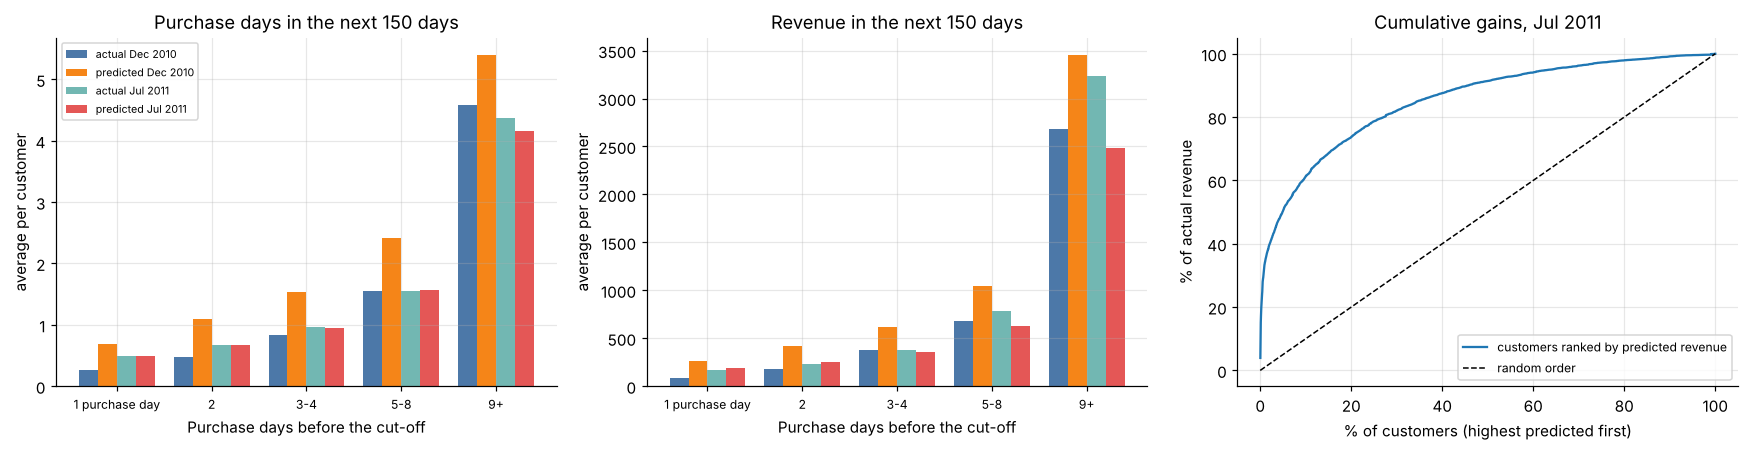

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
w = 0.2; xs = np.arange(len(LABELS))
for i, (c, (d, _, _)) in enumerate(backtests.items()):
    t = d.groupby("Group", observed=True).agg(p=("ExpPurchases150", "mean"), a=("ActualPurchases", "mean"), pr=("ExpRevenue150", "mean"), ar=("ActualRevenue", "mean"))
    ax[0].bar(xs + (2 * i - 1.5) * w, t["a"], w, label=f"actual {c:%b %Y}", color=["#4C78A8", "#72B7B2"][i])
    ax[0].bar(xs + (2 * i - 0.5) * w, t["p"], w, label=f"predicted {c:%b %Y}", color=["#F58518", "#E45756"][i])
    ax[1].bar(xs + (2 * i - 1.5) * w, t["ar"], w, color=["#4C78A8", "#72B7B2"][i], label=f"actual {c:%b %Y}")
    ax[1].bar(xs + (2 * i - 0.5) * w, t["pr"], w, color=["#F58518", "#E45756"][i], label=f"predicted {c:%b %Y}")
for a, title, yl in [(ax[0], "Purchase days in the next 150 days", "average per customer"), (ax[1], "Revenue in the next 150 days", "average per customer")]:
    a.set_xticks(xs); a.set_xticklabels(LABELS, fontsize=8); a.set_xlabel("Purchase days before the cut-off"); a.set_title(title); a.set_ylabel(yl)
ax[0].legend(fontsize=7)

d = backtests[TEST_CUTOFF][0].sort_values("ExpRevenue150", ascending=False).reset_index(drop=True)
share = np.arange(1, len(d) + 1) / len(d) * 100
gain = d["ActualRevenue"].cumsum() / d["ActualRevenue"].sum() * 100
ax[2].plot(share, gain, label="customers ranked by predicted revenue"); ax[2].plot([0, 100], [0, 100], "k--", lw=1, label="random order")
ax[2].set_xlabel("% of customers (highest predicted first)"); ax[2].set_ylabel("% of actual revenue"); ax[2].set_title(f"Cumulative gains, {TEST_CUTOFF:%b %Y}"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "clv_validation.png", dpi=120); plt.show()

### 8.1 CLV signals as churn predictors

Step 4 predicts churn with machine learning. The CLV model offers two natural churn signals from the same customer history: the **probability alive** and the **expected number of purchases** in the next 150 days (few expected purchases = likely churner). Their ROC-AUC against the real churn label is compared with the Step 4 model on the same test customers.

In [12]:
d = backtests[TEST_CUTOFF][0]
auc_ml = roc_auc_score(churn_test["Churn"], pred.loc[churn_test.index, "ChurnProbability"])
print(f"ROC-AUC for predicting churn on the {len(d):,} test customers:")
print(f"  Step 4 machine-learning model                : {auc_ml:.3f}")
print(f"  BG/NBD expected purchases (fewer = churn)    : {summary_bt[TEST_CUTOFF]['auc_exp_purchases']:.3f}")
print(f"  BG/NBD probability alive (lower = churn)     : {summary_bt[TEST_CUTOFF]['auc_palive']:.3f}")
once = d["PurchaseDays"] == 1
print(f"\nWhy the probability alive fails here: it equals 1 by construction for the {once.mean():.0%} of active customers with a single purchase day "
      f"(mean {d['PAlive'].mean():.2f}, {(d['PAlive'] > 0.99).mean():.0%} of customers above 0.99), so it hardly ranks them. Use expected purchases instead.")

ROC-AUC for predicting churn on the 4,313 test customers:
  Step 4 machine-learning model                : 0.775
  BG/NBD expected purchases (fewer = churn)    : 0.781
  BG/NBD probability alive (lower = churn)     : 0.491

Why the probability alive fails here: it equals 1 by construction for the 25% of active customers with a single purchase day (mean 0.91, 27% of customers above 0.99), so it hardly ranks them. Use expected purchases instead.


## 9. CLV by segment, and a first look at value versus churn risk

Combining the two Step 4 and Step 6 outputs previews the retention grid of Step 8: how much expected revenue sits with customers who are at high risk of churning, and how it divides by segment.

12-month CLV by segment:


,,Customers,MeanCLV,MedianCLV,TotalCLV,MeanExpPurchases12m,MeanPAlive,AvgPredictedChurn,ShareOfTotalCLV
SegmentID,Segment,,,,,,,,
1,Champions,698,"5,708.531","2,881.128","3,984,554.678",9.728,0.965,0.135,0.610
2,At-risk regulars,1284,"1,009.596",771.777,"1,296,321.697",2.589,0.832,0.521,0.198
3,Recent / developing customers,715,"1,011.865",839.437,"723,483.488",3.325,0.963,0.436,0.111
4,Lapsed low-frequency customers,1616,326.216,284.478,"527,164.500",1.123,0.930,0.683,0.081



Preview for Step 8 - number of customers and share of total CLV by churn risk (rows) and value tier (columns):


Value tier,High,Medium,Low
Churn risk,,,
High,4,28,831
Medium,11,257,1025
Low,847,1009,301


Value tier,High,Medium,Low
Churn risk,,,
High,0.200,0.400,3.200
Medium,0.400,3.200,6.000
Low,68.600,15.800,2.200


High-risk AND high-value customers: 4 customers holding 0.2% of the expected 12-month revenue.
Customers with a high CLV are almost all low-risk (847 of 862 high-value customers are in the Low risk tier), so a rule that needs 'High risk AND High value' applies to very few customers. Step 8 should rank at-risk customers by value at risk (CLV x churn probability) instead.


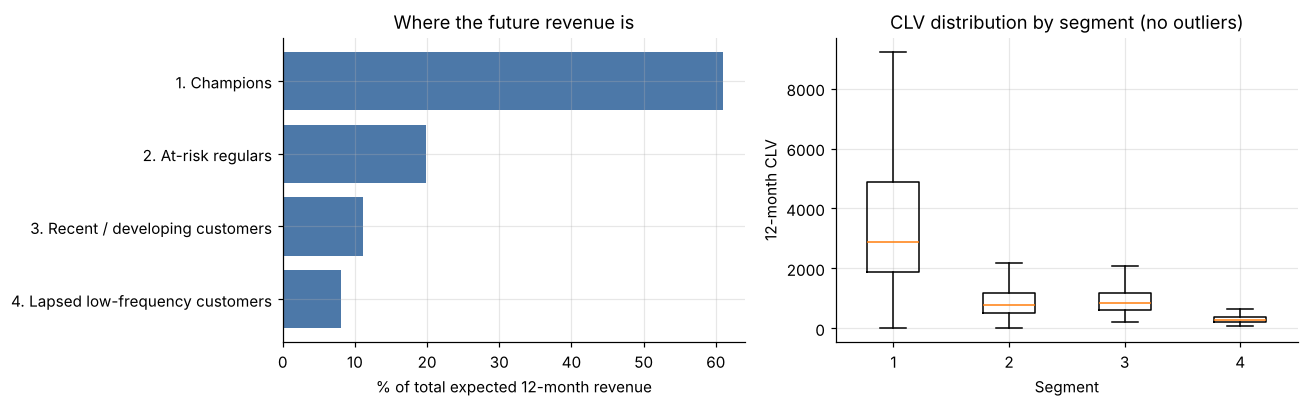

In [13]:
vt = clv_test.join(prof_df[["SegmentID", "Segment", "RiskTier", "ChurnProbability"]])
seg_clv = vt.groupby(["SegmentID", "Segment"]).agg(Customers=("CLV12m", "size"), MeanCLV=("CLV12m", "mean"), MedianCLV=("CLV12m", "median"),
                                                   TotalCLV=("CLV12m", "sum"), MeanExpPurchases12m=("ExpPurchases12m", "mean"),
                                                   MeanPAlive=("PAlive", "mean"), AvgPredictedChurn=("ChurnProbability", "mean"))
seg_clv["ShareOfTotalCLV"] = seg_clv["TotalCLV"] / seg_clv["TotalCLV"].sum()
print("12-month CLV by segment:")
display(seg_clv)

print("\nPreview for Step 8 - number of customers and share of total CLV by churn risk (rows) and value tier (columns):")
cnt = pd.crosstab(vt["RiskTier"], vt["ValueTier"]).reindex(index=["High", "Medium", "Low"], columns=["High", "Medium", "Low"])
share_clv = (vt.pivot_table(index="RiskTier", columns="ValueTier", values="CLV12m", aggfunc="sum").reindex(index=["High", "Medium", "Low"], columns=["High", "Medium", "Low"]) / vt["CLV12m"].sum())
display(cnt.rename_axis(index="Churn risk", columns="Value tier"))
display((share_clv * 100).rename_axis(index="Churn risk", columns="Value tier").round(1))
hh = share_clv.loc["High", "High"]
print(f"High-risk AND high-value customers: {cnt.loc['High', 'High']:,} customers holding {hh:.1%} of the expected 12-month revenue.")
print(f"Customers with a high CLV are almost all low-risk ({cnt.loc['Low', 'High']:,} of {cnt['High'].sum():,} high-value customers are in the Low risk tier), so a rule that needs "
      f"'High risk AND High value' applies to very few customers. Step 8 should rank at-risk customers by value at risk (CLV x churn probability) instead.")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
labels = [f"{i}. {n}" for i, n in seg_clv.index]
ax[0].barh(labels[::-1], seg_clv["ShareOfTotalCLV"].to_numpy()[::-1] * 100, color="#4C78A8"); ax[0].set_xlabel("% of total expected 12-month revenue"); ax[0].set_title("Where the future revenue is")
bp = [vt.loc[vt["SegmentID"] == s, "CLV12m"].clip(upper=vt["CLV12m"].quantile(0.99)) for s, _ in seg_clv.index]
ax[1].boxplot(bp, showfliers=False); ax[1].set_xticklabels([str(s) for s, _ in seg_clv.index]); ax[1].set_xlabel("Segment"); ax[1].set_ylabel("12-month CLV"); ax[1].set_title("CLV distribution by segment (no outliers)")
plt.tight_layout(); plt.savefig(FIG / "clv_by_segment.png", dpi=120); plt.show()

## 10. Optional: cross-check with the `lifetimes` package

If `lifetimes` is installed (`pip install lifetimes`; it may not work on the newest Python versions) this cell fits its BG/NBD and Gamma-Gamma models on the same data and compares the parameters with the implementation above. It is not needed for anything else, and the notebook continues if it is missing.

In [14]:
try:
    from lifetimes import BetaGeoFitter, GammaGammaFitter

    bgf = BetaGeoFitter(penalizer_coef=0.0).fit(summ_test["x"], summ_test["t_x"], summ_test["T"])
    ggf = GammaGammaFitter(penalizer_coef=0.0)
    mv = summ_test[summ_test["PurchaseDays"] > 0]
    print("BG/NBD   this notebook:", {k: round(v, 3) for k, v in bg_test.items()})
    print("BG/NBD   lifetimes    :", {k: round(float(v), 3) for k, v in bgf.params_.items()})
    print("(Gamma-Gamma is not compared: this notebook fits all purchase days, `lifetimes` fits repeat purchases only, so the parameters are not the same quantity.)")
except ImportError:
    print("The 'lifetimes' package is not installed - skipping this optional cross-check.")
except Exception as e:
    print("Optional cross-check skipped:", type(e).__name__, str(e)[:200])

The 'lifetimes' package is not installed - skipping this optional cross-check.


## 11. Save the results

* `customer_value_test.csv` - one row per churn-test customer (the same 4,313 as `churn_predictions_test.csv`): RFM, segment, BG/NBD inputs, probability alive, expected purchases, CLV and value tier. Join on `CustomerID`.
* `customer_value_current.csv` - the same for customers active at the **end of the data** (10 Dec 2011). The models are refitted on all data and segments are assigned with the centres learned above, so the segment definitions stay the same. Use this for today's retention list.
* `segment_profiles.csv` - the segment profile table (with CLV).
* `models/segmentation_clv_params.json` - everything needed to score new customers later (scaler, segment centres and names, model parameters, settings).

In [15]:
# ---- test snapshot
value_test = (elig_test[["Recency", "Frequency", "Monetary", "PurchaseDays", "x", "t_x", "T"]]
              .rename(columns={"x": "RepeatPurchaseDays", "t_x": "ActiveSpanDays", "T": "AgeDays"})
              .join(prof_df[["SegmentID", "Segment"]]).join(clv_test))
value_test.insert(0, "SnapshotDate", f"{TEST_CUTOFF:%Y-%m-%d}")
value_test = value_test.reset_index().rename(columns={"index": "CustomerID"})
assert value_test["CustomerID"].is_unique and set(value_test["CustomerID"]) == set(pred.index)
value_test.to_csv(DATA / "customer_value_test.csv", index=False)

# ---- current snapshot: end of the data, models refitted, segments assigned with the same centres
CURRENT_CUTOFF = sales["Day"].max() + pd.Timedelta(days=1)
summ_cur = customer_summary(sales, CURRENT_CUTOFF)
elig_cur = summ_cur[summ_cur["Active"]]
bg_cur, gg_cur = fit_clv_models(summ_cur)
clv_cur = add_tiers(predict_clv(elig_cur, bg_cur, gg_cur))
seg_cur = pd.Series(km.predict(scaler.transform(np.log1p(elig_cur[["Recency", "Frequency", "Monetary"]].to_numpy(float)))), index=elig_cur.index).map(relabel)
value_cur = (elig_cur[["Recency", "Frequency", "Monetary", "PurchaseDays", "x", "t_x", "T"]]
             .rename(columns={"x": "RepeatPurchaseDays", "t_x": "ActiveSpanDays", "T": "AgeDays"})
             .assign(SegmentID=seg_cur, Segment=seg_cur.map(SEGMENT_NAMES)).join(clv_cur))
value_cur.insert(0, "SnapshotDate", f"{CURRENT_CUTOFF:%Y-%m-%d}")
value_cur = value_cur.reset_index().rename(columns={"index": "CustomerID"})
value_cur.to_csv(DATA / "customer_value_current.csv", index=False)

# ---- profile table with CLV, and parameters
profile_out = prof.join(seg_clv.reset_index(level=1, drop=True)[["MeanCLV", "MedianCLV", "TotalCLV", "ShareOfTotalCLV", "MeanPAlive"]]).reset_index()
profile_out.to_csv(DATA / "segment_profiles.csv", index=False)

params = {"created_for_cutoff": f"{TEST_CUTOFF:%Y-%m-%d}",
          "segmentation": {"features": ["Recency", "Frequency", "Monetary"], "transform": "log1p then standardise", "k": int(best_k),
                           "scaler_mean": scaler.mean_.tolist(), "scaler_scale": scaler.scale_.tolist(),
                           "centers_scaled": centers.tolist(), "segment_ids": [int(s) for s in sorted(SEGMENT_NAMES)],
                           "segment_names": {str(s): n for s, n in SEGMENT_NAMES.items()}},
          "clv": {"horizon_months": CLV_MONTHS, "days_per_month": DAYS_PER_MONTH, "discount_monthly": DISCOUNT_MONTHLY,
                  "tier_split_high_medium_low": list(TIER_SPLIT), "unit": "revenue (no margin data)",
                  "bgnbd_test_cutoff": {k: float(v) for k, v in bg_test.items()}, "gammagamma_test_cutoff": {k: float(v) for k, v in gg_test.items()},
                  "bgnbd_current": {k: float(v) for k, v in bg_cur.items()}, "gammagamma_current": {k: float(v) for k, v in gg_cur.items()}}}
(MODELS / "segmentation_clv_params.json").write_text(json.dumps(params, indent=2), encoding="utf-8")

for f in ("customer_value_test.csv", "customer_value_current.csv", "segment_profiles.csv", "clv_validation.csv"):
    print(f"saved data/{f}  ({(DATA / f).stat().st_size / 1e6:.2f} MB)")
print("saved models/segmentation_clv_params.json")
print(f"\nCurrent snapshot {CURRENT_CUTOFF:%d %b %Y}: {len(value_cur):,} active customers; BG/NBD {{ {', '.join(f'{k} {v:.2f}' for k, v in bg_cur.items())} }}")
display(value_cur.groupby("Segment").agg(Customers=("CustomerID", "size"), MeanCLV=("CLV12m", "mean"), TotalCLV=("CLV12m", "sum")))
display(value_test.sort_values("CLV12m", ascending=False).head(5)[["CustomerID", "Segment", "Recency", "Frequency", "Monetary", "ExpPurchases12m", "ExpValuePerPurchase", "CLV12m", "ValueTier"]])

saved data/customer_value_test.csv  (0.82 MB)
saved data/customer_value_current.csv  (0.81 MB)
saved data/segment_profiles.csv  (0.00 MB)
saved data/clv_validation.csv  (0.00 MB)
saved models/segmentation_clv_params.json

Current snapshot 10 Dec 2011: 4,260 active customers; BG/NBD { r 0.67, alpha 64.00, a 0.11, b 2.43 }


,Customers,MeanCLV,TotalCLV
Segment,,,
At-risk regulars,1100,950.198,"1,045,217.717"
Champions,1052,"5,054.250","5,317,070.895"
Lapsed low-frequency customers,983,373.070,"366,727.355"
Recent / developing customers,1125,"1,086.180","1,221,952.940"


,CustomerID,Segment,Recency,Frequency,Monetary,ExpPurchases12m,ExpValuePerPurchase,CLV12m,ValueTier
4189,18102,Champions,17,105,"427,931.290",27.591,"8,078.273","209,188.816",High
1664,14646,Champions,3,105,"383,057.610",37.033,"5,476.188","190,336.415",High
1279,14156,Champions,2,115,"239,959.820",49.934,"2,556.392","119,806.380",High
3721,17450,Champions,15,20,"111,559.200",14.283,"6,987.551","93,701.343",High
1856,14911,Champions,1,251,"179,764.560",94.732,"1,017.741","90,489.170",High


## 12. Summary of findings

In [16]:
b = summary_bt[TEST_CUTOFF]; b0 = summary_bt[BACKTEST_CUTOFFS[0]]
lines = [
    f"Segmentation: K-Means on log-scaled, standardised RFM of the {len(elig_test):,} active customers at {TEST_CUTOFF:%d %b %Y}; k = {best_k} chosen by silhouette among k >= {K_MIN} "
    f"(silhouette {k_table.loc[best_k, 'Silhouette']:.2f}, stability ARI {k_table.loc[best_k, 'Stability (ARI)']:.2f}); structure is a continuum, so segments are practical divisions.",
]
for s, r in prof.iterrows():
    lines.append(f"Segment {s} {r['Segment']}: {r['Customers']:,.0f} customers ({r['ShareOfCustomers']:.0%}), {r['ShareOfPastSpend']:.0%} of past spend, "
                 f"last purchase a median {r['MedianRecency']:.0f} days ago, {r['MedianFrequency']:.0f} orders; {r['ActualChurnRate']:.0%} churned afterwards; "
                 f"mean 12-month CLV {seg_clv.loc[(s, r['Segment']), 'MeanCLV']:,.0f}.")
lines += [
    f"CLV model: BG/NBD (r {bg_test['r']:.2f}, alpha {bg_test['alpha']:.1f}, a {bg_test['a']:.2f}, b {bg_test['b']:.2f}) + Gamma-Gamma (p {gg_test['p']:.2f}, q {gg_test['q']:.2f}, gamma {gg_test['gamma']:.0f}); "
    f"CLV = expected revenue over {CLV_MONTHS} months, {DISCOUNT_MONTHLY:.0%}/month discount, no margin data; Gamma-Gamma independence check correlation {r_p:.2f}.",
    f"Total expected 12-month revenue of the active customers {tot:,.0f}; the top 20% by CLV hold {top20:.0%}.",
    f"Backtest {TEST_CUTOFF:%b %Y}: predicted/actual purchase days {b['purchase_ratio']:.2f}, revenue {b['revenue_ratio']:.2f} ({b['revenue_ratio_ex_top1pct']:.2f} without the top 1% of spenders); "
    f"rank correlation {b['spearman_purchases']:.2f} (purchases) and {b['spearman_revenue']:.2f} (revenue); the top 10/20/30% by predicted revenue deliver {b['capture10']:.0%}/{b['capture20']:.0%}/{b['capture30']:.0%} of actual revenue.",
    f"Backtest {BACKTEST_CUTOFFS[0]:%b %Y}: purchase ratio {b0['purchase_ratio']:.2f}, revenue ratio {b0['revenue_ratio']:.2f}, rank correlation {b0['spearman_purchases']:.2f}/{b0['spearman_revenue']:.2f}.",
    f"Churn signal: ROC-AUC {b['auc_exp_purchases']:.3f} for BG/NBD expected purchases, {b['auc_palive']:.3f} for probability alive (equals 1 for single-purchase customers), {auc_ml:.3f} for the Step 4 model.",
    f"High-risk AND high-value customers: {cnt.loc['High', 'High']:,} holding {hh:.1%} of expected 12-month revenue; high-value customers are almost all low churn risk, so Step 8 should prioritise by value at risk (CLV x churn probability).",
    f"Calibration depends on the cut-off: predicted/actual purchase days {b['purchase_ratio']:.2f} at {TEST_CUTOFF:%b %Y} but {b0['purchase_ratio']:.2f} at {BACKTEST_CUTOFFS[0]:%b %Y} (no seasonal term in the model). Use CLV mainly to rank and tier customers; revenue is not profit.",
]
print("KEY FINDINGS")
print("=" * 60)
for i, l in enumerate(lines, 1):
    print(f"{i}. {l}")
Path("segmentation_clv_summary.txt").write_text("\n".join(f"{i}. {l}" for i, l in enumerate(lines, 1)), encoding="utf-8")
print("\nSaved segmentation_clv_summary.txt")

KEY FINDINGS
1. Segmentation: K-Means on log-scaled, standardised RFM of the 4,313 active customers at 01 Jul 2011; k = 4 chosen by silhouette among k >= 3 (silhouette 0.37, stability ARI 0.97); structure is a continuum, so segments are practical divisions.
2. Segment 1 Champions: 698 customers (16%), 66% of past spend, last purchase a median 21 days ago, 14 orders; 7% churned afterwards; mean 12-month CLV 5,709.
3. Segment 2 At-risk regulars: 1,284 customers (30%), 23% of past spend, last purchase a median 148 days ago, 5 orders; 43% churned afterwards; mean 12-month CLV 1,010.
4. Segment 3 Recent / developing customers: 715 customers (17%), 6% of past spend, last purchase a median 22 days ago, 3 orders; 34% churned afterwards; mean 12-month CLV 1,012.
5. Segment 4 Lapsed low-frequency customers: 1,616 customers (37%), 5% of past spend, last purchase a median 225 days ago, 1 orders; 70% churned afterwards; mean 12-month CLV 326.
6. CLV model: BG/NBD (r 0.67, alpha 65.7, a 0.16, b 3.13

## How to use these results, and limits to state in the report

**For Step 8 (retention framework) and Step 10 (dashboard)**
* Join `data/customer_value_test.csv` with `data/churn_predictions_test.csv` on `CustomerID`. `ValueTier` (High / Medium / Low) and `RiskTier` use the same 20/30/50 split, so the rule examples in the plan work directly (for example *High risk + High value* = personal outreach). Use `CLV12m` for the money amount and `Segment` for messaging.
* `data/customer_value_current.csv` holds the same fields for customers active at the end of the data. The churn model has to be scored on a snapshot at that date (Step 8) to pair with it.

**Limits to state**
* **CLV is expected revenue, not profit.** The data has no costs or margins. If a margin is known, multiply `CLV12m` by it.
* **Use CLV mainly for ranking and tiering.** The ranking of customers is similar in both backtests, but the *level* of the predictions is not: at the 1 July 2011 cut-off predicted purchases are close to actual ones (and revenue is somewhat low for the biggest buyers, because spending is heavy-tailed and Gamma-Gamma pulls large customers towards the average), while at the 31 December 2010 cut-off the model clearly over-predicts, most likely because the model has no seasonal term and learns from a history that ends with the Christmas peak.
* **Seasonality and a short history.** The data covers about two Christmas-heavy years and the models have no seasonal term; the history starts in December 2009, so a customer's "first purchase" may not be their true first purchase (the same left-censoring caveat as `Tenure` in the SHAP step).
* **Wholesale customers.** Many customers are businesses with very large orders. Segments are practical divisions of a continuum (the silhouette is moderate), and the probability alive is not a useful churn signal here.
* **High value means low churn risk here.** Almost no customer is both High value and High churn risk, so retention rules should use value at risk (CLV x churn probability) or value tiers *within* each risk group.
* **Segments are fitted at one snapshot (1 July 2011)** and reused for the current snapshot so the definitions stay stable; refit them if the customer base changes a lot.